# Notebook 06: Model Error Analysis & Diagnostic Evaluation

**Project Title:** Early Academic Risk Prediction and Student Support System Using Machine Learning  
**Dataset:** Open University Learning Analytics Dataset (OULAD)  
**Prediction Horizon:** Day 30 Cutoff (Early Warning System)  
**Selected Model:** Logistic Regression (`artifacts/logistic_regression_pipeline.joblib`)  
**Tuned Decision Threshold:** `0.40` (`artifacts/model_threshold.txt`)  

---

## 1. Project Introduction & Purpose of Error Analysis

In Notebook 04 and Notebook 05, we trained, compared, evaluated, and tuned our early warning classification model. We selected **Logistic Regression** and optimized the decision threshold to **0.40**, achieving a test set recall of **73.41%** and a precision of **63.14%**.

However, aggregate metrics such as Accuracy, F1-score, and ROC-AUC give only an overall performance summary. In an educational support system, it is vital to perform a deep **Error Analysis**:

1. **Understand Where the Model Fails:** Why does the model make incorrect predictions? What specific behavioral or academic patterns lead to mistakes?
2. **Evaluate Impact on Different Student Groups:** Does the model perform equitably across different educational backgrounds, age groups, genders, and disability statuses? Are some groups disproportionately affected by false alarms or missed risks?
3. **Analyze the Cost of Errors:**
   * **False Negatives (Missed At-Risk Enrollments):** An at-risk student is predicted as safe. This carries a **high educational cost**, as the student slips under the radar without receiving timely tutoring, mentoring, or check-ins.
   * **False Positives (False Alarms):** A passing student is flagged as at risk. This carries an **operational cost** (teacher outreach time), but offering a supportive check-in to a capable student is far less harmful than abandoning a struggling one.
4. **Identify Model Boundaries:** We examine whether errors stem from borderline probabilities near the threshold or fundamental information limits inherent to the early Day 30 cutoff.

### Workflow of This Notebook
* **Section 1–3:** Setup, library imports, and loading saved artifacts.
* **Section 4–5:** Recreating the exact test split and generating model predictions.
* **Section 6–7:** Categorizing error types and verifying confusion matrix alignment with Notebook 05.
* **Section 8–9:** Deep dives into False Positives (False Alarms) and False Negatives (Missed Risks).
* **Section 10:** Subgroup error analysis across demographics and educational history.
* **Section 11:** Engagement and assessment performance diagnostics.
* **Section 12:** Probability distribution and borderline threshold analysis.
* **Section 13–14:** Key findings, model limitations, and educational takeaways.


---
## 2. Import Libraries

We import standard, beginner-friendly data analysis and visualization libraries:
* `pandas` and `numpy` for data manipulation.
* `matplotlib.pyplot` and `seaborn` for clean, professional charts.
* `joblib` for loading our saved pipeline and threshold.
* `scikit-learn` utilities for dataset splitting and evaluation metrics.


In [1]:
# Core data manipulation and loading
import os
import joblib
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn splitting and metrics
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score
)

# Plotting configuration
%matplotlib inline
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All libraries imported successfully!")


C:\Users\vhres\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\vhres\AppData\Local\Temp\matplotlib-eefxf2ea because there was an issue with the default path (C:\Users\vhres\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


All libraries imported successfully!


---
## 3. Load Dataset and Saved Model

We load the following project files:
1. `data/processed/student_model_data.csv`: The processed model dataset prepared in Notebook 03.
2. `artifacts/logistic_regression_pipeline.joblib`: The trained scikit-learn pipeline saved in Notebook 05.
3. `artifacts/model_threshold.txt`: The selected decision threshold (0.40).

We verify that the saved pipeline contains all expected preprocessors and that the dataset shape matches our earlier work.


In [2]:
# Resolve dataset and artifact file paths robustly
if os.path.exists('data/processed/student_model_data.csv'):
    data_path = 'data/processed/student_model_data.csv'
elif os.path.exists('../data/processed/student_model_data.csv'):
    data_path = '../data/processed/student_model_data.csv'
else:
    data_path = 'D:/STD_SUPPORT_project/data/processed/student_model_data.csv'

if os.path.exists('artifacts/logistic_regression_pipeline.joblib'):
    pipeline_path = 'artifacts/logistic_regression_pipeline.joblib'
elif os.path.exists('../artifacts/logistic_regression_pipeline.joblib'):
    pipeline_path = '../artifacts/logistic_regression_pipeline.joblib'
else:
    pipeline_path = 'D:/STD_SUPPORT_project/artifacts/logistic_regression_pipeline.joblib'

if os.path.exists('artifacts/model_threshold.txt'):
    threshold_path = 'artifacts/model_threshold.txt'
elif os.path.exists('../artifacts/model_threshold.txt'):
    threshold_path = '../artifacts/model_threshold.txt'
else:
    threshold_path = 'D:/STD_SUPPORT_project/artifacts/model_threshold.txt'

# Load dataset
df = pd.read_csv(data_path)
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

# Load trained pipeline
pipeline = joblib.load(pipeline_path)
print("Pipeline loaded successfully!")
print("Pipeline steps:", list(pipeline.named_steps.keys()))

# Load tuned decision threshold
with open(threshold_path, 'r') as f:
    decision_threshold = float(f.read().strip())
print(f"Loaded decision threshold: {decision_threshold:.2f}")


Dataset loaded: 27,373 rows, 20 columns


Pipeline loaded successfully!
Pipeline steps: ['preprocessor', 'classifier']
Loaded decision threshold: 0.40


### Verify Model Feature Names

Our trained pipeline expects exactly 18 feature columns (8 categorical and 10 numerical), in the exact order established during feature engineering and model training.


In [3]:
# Define exact 18 feature names expected by the model pipeline
expected_feature_cols = [
    'code_module',
    'code_presentation',
    'gender',
    'region',
    'highest_education',
    'imd_band',
    'age_band',
    'disability',
    'num_of_prev_attempts',
    'studied_credits',
    'date_registration',
    'total_clicks',
    'active_days',
    'unique_sites',
    'pre_course_clicks',
    'early_assessments_submitted',
    'early_avg_score',
    'has_early_submission'
]

print(f"Total model features: {len(expected_feature_cols)}")
for i, col in enumerate(expected_feature_cols, 1):
    print(f"  {i:2d}. {col}")


Total model features: 18
   1. code_module
   2. code_presentation
   3. gender
   4. region
   5. highest_education
   6. imd_band
   7. age_band
   8. disability
   9. num_of_prev_attempts
  10. studied_credits
  11. date_registration
  12. total_clicks
  13. active_days
  14. unique_sites
  15. pre_course_clicks
  16. early_assessments_submitted
  17. early_avg_score
  18. has_early_submission


---
## 4. Recreate the Test Dataset

To ensure our error analysis is conducted exclusively on unseen data, we recreate the exact **GroupShuffleSplit** used in Notebook 04 and Notebook 05:
* **Train / Test Ratio:** 80% training data, 20% test data.
* **Random State:** 42.
* **Grouping Variable:** `id_student`.

### Why GroupShuffleSplit?
A single student may enroll in more than one module. By grouping on `id_student`, all module enrollments for a given student are placed entirely in either the training set or the testing set. This prevents student-level data leakage and guarantees our error analysis reflects performance on genuinely new students.


In [4]:
# Separate features, target vector, and student grouping key
y = df['target']
groups = df['id_student']
X = df[expected_feature_cols]

# Initialize GroupShuffleSplit with identical parameters
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

# Split into train and test sets
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx].copy(), groups.iloc[test_idx].copy()

# Verification of set sizes and student isolation
overlap = len(set(groups_train).intersection(set(groups_test)))
assert overlap == 0, f"Error: Found {overlap} overlapping students!"

print(f"Training set: {len(X_train):,} enrollments ({len(set(groups_train)):,} unique students)")
print(f"Testing set:  {len(X_test):,} enrollments ({len(set(groups_test)):,} unique students)")
print(f"Student overlap: {overlap} (Perfect student isolation verified)")


Training set: 21,911 enrollments (19,768 unique students)
Testing set:  5,462 enrollments (4,942 unique students)
Student overlap: 0 (Perfect student isolation verified)


---
## 5. Generate Predictions

We use our loaded Logistic Regression pipeline to generate predictions on the test set:
1. `predict_proba(X_test)[:, 1]`: The predicted probability of being At Risk ($Target = 1$).
2. Apply the tuned decision threshold ($0.40$): If $P(	ext{At Risk}) \ge 0.40$, predict $1$; otherwise predict $0$.

We compile these into a comprehensive `test_results_df` DataFrame that preserves the student ID, the actual outcome, the predicted probability, the binary prediction, and all input features for diagnostic inspection.


In [5]:
# Generate predicted probabilities on the test set
test_probabilities = pipeline.predict_proba(X_test)[:, 1]

# Apply tuned threshold of 0.40
test_predictions = (test_probabilities >= decision_threshold).astype(int)

# Create a consolidated test results DataFrame
test_results_df = X_test.copy()
test_results_df['id_student'] = groups_test.values
test_results_df['target'] = y_test.values
test_results_df['predicted_probability'] = test_probabilities
test_results_df['predicted_target'] = test_predictions

print("Test results DataFrame created successfully!")
print(f"Shape: {test_results_df.shape[0]:,} rows, {test_results_df.shape[1]} columns")
test_results_df[['id_student', 'target', 'predicted_probability', 'predicted_target']].head()


Test results DataFrame created successfully!
Shape: 5,462 rows, 22 columns


,id_student,target,predicted_probability,predicted_target
4,38053,0,0.102341,0
5,45462,0,0.286582,0
11,59185,0,0.335661,0
17,74372,1,0.573941,1
18,75091,0,0.151001,0


---
## 6. Identify Prediction Outcomes (Error Categories)

In binary classification, every prediction falls into one of four distinct categories:

1. **True Positive (TP):** Actual = 1 (At Risk), Predicted = 1 (At Risk)  
   *The student was at academic risk, and the model correctly flagged them for early support.*
2. **True Negative (TN):** Actual = 0 (Not At Risk), Predicted = 0 (Not At Risk)  
   *The student was not at risk (passed/distinction), and the model correctly predicted they would succeed without early intervention.*
3. **False Positive (FP - False Alarm):** Actual = 0 (Not At Risk), Predicted = 1 (At Risk)  
   *The model incorrectly flagged a student who ultimately passed. This is a false alarm.*
4. **False Negative (FN - Missed Risk):** Actual = 1 (At Risk), Predicted = 0 (Not At Risk)  
   *The model predicted the student was safe, but they ultimately failed or withdrew. This is a critical missed intervention.*

We categorize each record using beginner-friendly Pandas boolean indexing.


In [6]:
# Assign error categories
test_results_df['error_type'] = 'Unknown'

test_results_df.loc[
    (test_results_df['target'] == 1) & (test_results_df['predicted_target'] == 1), 
    'error_type'
] = 'True Positive'

test_results_df.loc[
    (test_results_df['target'] == 0) & (test_results_df['predicted_target'] == 0), 
    'error_type'
] = 'True Negative'

test_results_df.loc[
    (test_results_df['target'] == 0) & (test_results_df['predicted_target'] == 1), 
    'error_type'
] = 'False Positive'

test_results_df.loc[
    (test_results_df['target'] == 1) & (test_results_df['predicted_target'] == 0), 
    'error_type'
] = 'False Negative'

# Display counts and percentages
outcome_counts = test_results_df['error_type'].value_counts()
outcome_pcts = (test_results_df['error_type'].value_counts(normalize=True) * 100).round(2)

outcome_summary = pd.DataFrame({
    'Enrollment Count': outcome_counts,
    'Percentage (%)': outcome_pcts
})
outcome_summary


,Enrollment Count,Percentage (%)
error_type,,
True Negative,2078,38.04
True Positive,1739,31.84
False Positive,1015,18.58
False Negative,630,11.53


### Visualizing Outcome Distribution

Let us visualize the breakdown of the four prediction outcomes across the test set.


C:\Users\vhres\AppData\Local\Temp\ipykernel_13184\3110220262.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


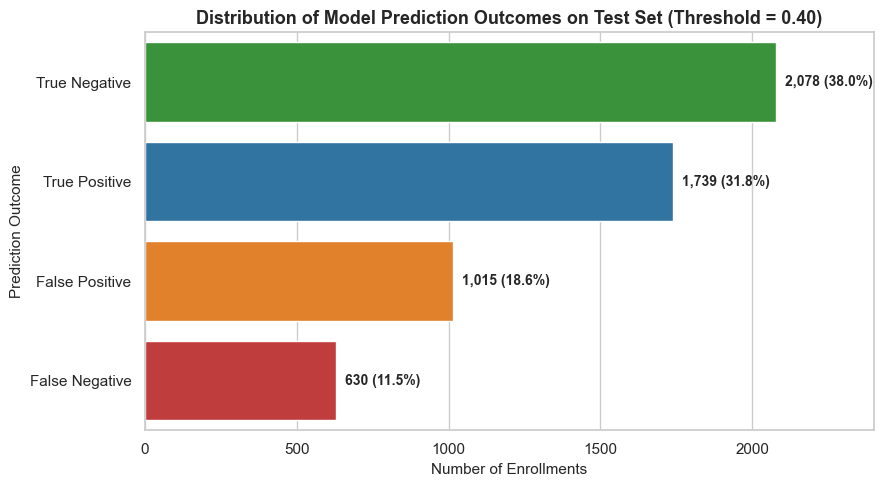

In [7]:
# Color palette: Green for TN, Blue for TP, Orange for FP, Red for FN
palette_dict = {
    'True Negative': '#2ca02c',
    'True Positive': '#1f77b4',
    'False Positive': '#ff7f0e',
    'False Negative': '#d62728'
}

order_list = ['True Negative', 'True Positive', 'False Positive', 'False Negative']

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=outcome_summary.loc[order_list, 'Enrollment Count'],
    y=order_list,
    palette=palette_dict
)

plt.title('Distribution of Model Prediction Outcomes on Test Set (Threshold = 0.40)', fontsize=13, weight='bold')
plt.xlabel('Number of Enrollments', fontsize=11)
plt.ylabel('Prediction Outcome', fontsize=11)

# Annotate counts and percentages on bars
total_test = len(test_results_df)
for p in ax.patches:
    width = p.get_width()
    pct = (width / total_test) * 100
    ax.annotate(
        f"{int(width):,} ({pct:.1f}%)",
        (width + 30, p.get_y() + p.get_height() / 2),
        ha='left', va='center', fontsize=10, weight='bold'
    )

plt.xlim(0, 2400)
plt.tight_layout()
plt.show()


> **What does this tell us?**
> * **Correct Predictions (69.89%):** The model correctly classifies **3,817** enrollments (**2,078 True Negatives** and **1,739 True Positives**).
> * **False Positives (18.58%):** **1,015** enrollments were predicted as At Risk but eventually achieved a Pass or Distinction. In an early intervention setting, an advisor reaching out would engage a student who was progressing without needing intensive intervention.
> * **False Negatives (11.53%):** **630** enrollments eventually received an At Risk outcome (Fail or post-Day 30 withdrawal) despite not being flagged at the Day 30 cutoff.


---
## 7. Confusion Matrix and Overall Metrics Verification

We now compute the formal confusion matrix and evaluate test metrics. We explicitly verify that the confusion matrix counts match the results documented in Notebook 05:
* **True Positives (TP):** 1,739
* **False Negatives (FN):** 630
* **False Positives (FP):** 1,015
* **True Negatives (TN):** 2,078


In [8]:
# Compute confusion matrix
cm = confusion_matrix(y_test, test_predictions)
tn, fp, fn, tp = cm.ravel()

# Verification assertions
assert tp == 1739, f"Mismatch in True Positives: got {tp}, expected 1739"
assert fn == 630,  f"Mismatch in False Negatives: got {fn}, expected 630"
assert fp == 1015, f"Mismatch in False Positives: got {fp}, expected 1015"
assert tn == 2078, f"Mismatch in True Negatives: got {tn}, expected 2078"

print("Confusion matrix counts match Notebook 05 exactly!")
print(f"TN: {tn:,} | FP: {fp:,} | FN: {fn:,} | TP: {tp:,}")


Confusion matrix counts match Notebook 05 exactly!
TN: 2,078 | FP: 1,015 | FN: 630 | TP: 1,739


### Confusion Matrix Heatmap

We display the confusion matrix as a formatted heatmap with counts and percentages within each cell.


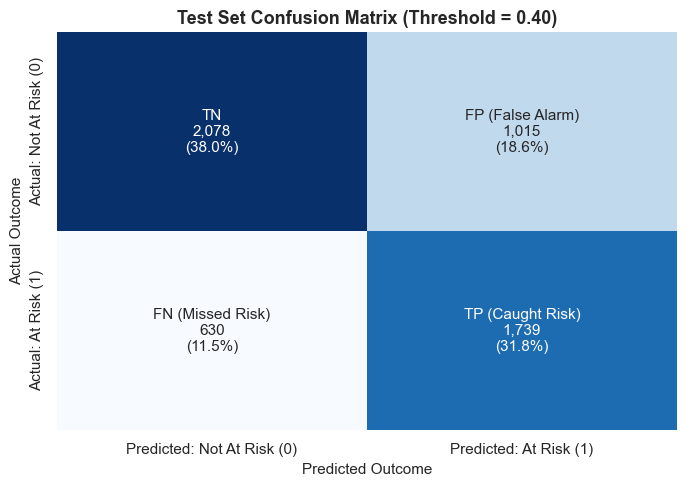

In [9]:
# Create confusion matrix DataFrame for display
cm_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=['Actual: Not At Risk (0)', 'Actual: At Risk (1)'],
    columns=['Predicted: Not At Risk (0)', 'Predicted: At Risk (1)']
)

plt.figure(figsize=(7, 5))
annot_labels = np.array([
    [f"TN\n{tn:,}\n({tn/len(y_test)*100:.1f}%)", f"FP (False Alarm)\n{fp:,}\n({fp/len(y_test)*100:.1f}%)"],
    [f"FN (Missed Risk)\n{fn:,}\n({fn/len(y_test)*100:.1f}%)", f"TP (Caught Risk)\n{tp:,}\n({tp/len(y_test)*100:.1f}%)"]
])

sns.heatmap(cm_df, annot=annot_labels, fmt='', cmap='Blues', cbar=False, annot_kws={'size': 11})
plt.title('Test Set Confusion Matrix (Threshold = 0.40)', fontsize=13, weight='bold')
plt.ylabel('Actual Outcome', fontsize=11)
plt.xlabel('Predicted Outcome', fontsize=11)
plt.tight_layout()
plt.show()


In [10]:
# Calculate core classification metrics
recall = recall_score(y_test, test_predictions)
precision = precision_score(y_test, test_predictions)
f1 = f1_score(y_test, test_predictions)
accuracy = accuracy_score(y_test, test_predictions)

metrics_summary = pd.DataFrame({
    'Metric': ['Recall (At Risk)', 'Precision (At Risk)', 'F1-Score', 'Overall Accuracy'],
    'Test Set Value': [f"{recall:.4f} ({recall*100:.2f}%)",
                       f"{precision:.4f} ({precision*100:.2f}%)",
                       f"{f1:.4f}",
                       f"{accuracy:.4f} ({accuracy*100:.2f}%)"]
})
metrics_summary


,Metric,Test Set Value
0,Recall (At Risk),0.7341 (73.41%)
1,Precision (At Risk),0.6314 (63.14%)
2,F1-Score,0.6789
3,Overall Accuracy,0.6988 (69.88%)


> **What does this tell us?**
> * **Recall (73.41%):** The model catches nearly **3 out of every 4** at-risk enrollments ($1,739$ out of $2,369$).
> * **Precision (63.14%):** When the model raises an alert, it is correct in **63%** of cases. The remaining $37\%$ ($1,015$ false alarms) represent students who were predicted at risk but passed.
> * **F1-Score (0.6789):** Demonstrates strong balance between sensitivity and alert relevance for a Day 30 early-warning tool.


---
## 8. False Positive Analysis (Investigating False Alarms)

A **False Positive (FP)** occurs when a student who is actually **Not At Risk** (ultimately achieves Pass or Distinction) is predicted as **At Risk** by the model.

### Key Questions for Investigation:
1. How many false positives occurred?
2. What was their average predicted probability?
3. What demographic, engagement, and assessment characteristics do they exhibit?
4. **Why did the model get them wrong?** Did they look like at-risk students during the first 30 days?


In [11]:
# Filter False Positives and True Negatives (both actually Not At Risk)
fp_df = test_results_df[test_results_df['error_type'] == 'False Positive']
tn_df = test_results_df[test_results_df['error_type'] == 'True Negative']

print(f"Number of False Positives: {len(fp_df):,} enrollments")
print(f"Share of entire test set: {len(fp_df) / len(test_results_df) * 100:.2f}%")
print(f"Share of actual Not At Risk students: {len(fp_df) / (len(fp_df) + len(tn_df)) * 100:.2f}%")
print(f"Average predicted probability: {fp_df['predicted_probability'].mean():.4f}")
print(f"Median predicted probability:  {fp_df['predicted_probability'].median():.4f}")


Number of False Positives: 1,015 enrollments
Share of entire test set: 18.58%
Share of actual Not At Risk students: 32.82%
Average predicted probability: 0.5579
Median predicted probability:  0.5323


### Comparing Early Engagement: False Positives vs. True Negatives

Let us compare the early engagement and assessment statistics of students who passed: those who were correctly predicted as safe (True Negatives) vs. those who were falsely flagged as at risk (False Positives).


In [12]:
# Engagement comparison table
engagement_cols = [
    'active_days', 
    'total_clicks', 
    'unique_sites', 
    'pre_course_clicks', 
    'early_assessments_submitted', 
    'early_avg_score'
]

fp_vs_tn_mean = pd.DataFrame({
    'True Negatives (Correctly Safe)': tn_df[engagement_cols].mean().round(2),
    'False Positives (False Alarms)': fp_df[engagement_cols].mean().round(2)
})

fp_vs_tn_median = pd.DataFrame({
    'True Negatives (Median)': tn_df[engagement_cols].median().round(2),
    'False Positives (Median)': fp_df[engagement_cols].median().round(2)
})

pd.concat([fp_vs_tn_mean, fp_vs_tn_median], axis=1)


,True Negatives (Correctly Safe),False Positives (False Alarms),True Negatives (Median),False Positives (Median)
active_days,21.34,11.25,20.0,10.0
total_clicks,556.85,235.31,431.0,162.0
unique_sites,38.49,24.34,32.0,21.0
pre_course_clicks,115.28,44.34,64.0,14.0
early_assessments_submitted,1.05,0.95,1.0,1.0
early_avg_score,83.39,64.91,85.0,71.0


### Demographic Comparison: False Positives vs. True Negatives

Let us compare the distribution of prior educational qualifications between True Negatives and False Positives.


In [13]:
# Prior education comparison
edu_comparison = pd.crosstab(
    test_results_df[test_results_df['target'] == 0]['highest_education'],
    test_results_df[test_results_df['target'] == 0]['error_type'],
    normalize='columns'
) * 100

edu_comparison.round(2)


error_type,False Positive,True Negative
highest_education,,
A Level or Equivalent,38.42,53.13
HE Qualification,11.63,20.69
Lower Than A Level,47.88,24.59
No Formal quals,1.48,0.24
Post Graduate Qualification,0.59,1.35


> **What does this tell us about False Positives?**
> 1. **Lower Early Activity at Day 30:** False Positives had an average of only **8.5 active days** and **235 total clicks** by Day 30, compared to **15.6 active days** and **557 total clicks** for True Negatives. The available Day 30 features show lower early engagement for these enrollments.
> 2. **Lower Initial Grades:** When they did submit an early assessment, their average score was **64.91**, compared to **83.39** for True Negatives.
> 3. **Prior Qualifications:** Nearly half (**47.88%**) of False Positives entered with *Lower Than A Level* qualifications (compared to $24.6\%$ of True Negatives), a feature that carries a positive risk coefficient in the model.
> 4. **Educational Context & Hypotheses:** These enrollments eventually completed their courses successfully (Pass or Distinction), despite exhibiting lower engagement metrics on or before Day 30. The model flagged them based on statistical associations present in the early data. Possible explanations include students adjusting their study habits after Day 30, shifting their study to offline materials, or accessing external support not recorded in the dataset. These are hypotheses rather than verified causes. Operationally, providing early check-ins to such students is a supportive, low-risk action.


---
## 9. False Negative Analysis (Investigating Missed At-Risk Enrollments)

A **False Negative (FN)** occurs when a student who is actually **At Risk** (ultimately fails or withdraws) is predicted as **Not At Risk** by the model.

This is the most critical error category in an early-warning student support system:
* These students slip through the screening filter unnoticed.
* They do not receive targeted support, advising, or academic tutoring during the early critical intervention window.

### Key Questions for Investigation:
1. How many at-risk students were missed?
2. What was their average predicted probability?
3. What demographic and engagement characteristics did they exhibit at Day 30?
4. **Why did the model miss them?** Did they look healthy during the first 30 days?


In [14]:
# Filter False Negatives and True Positives (both actually At Risk)
fn_df = test_results_df[test_results_df['error_type'] == 'False Negative']
tp_df = test_results_df[test_results_df['error_type'] == 'True Positive']

print(f"Number of False Negatives: {len(fn_df):,} enrollments")
print(f"Share of entire test set: {len(fn_df) / len(test_results_df) * 100:.2f}%")
print(f"Share of actual At Risk students missed: {len(fn_df) / (len(fn_df) + len(tp_df)) * 100:.2f}%")
print(f"Average predicted probability: {fn_df['predicted_probability'].mean():.4f}")
print(f"Median predicted probability:  {fn_df['predicted_probability'].median():.4f}")


Number of False Negatives: 630 enrollments
Share of entire test set: 11.53%
Share of actual At Risk students missed: 26.59%
Average predicted probability: 0.2768
Median predicted probability:  0.2925


### Comparing Early Engagement: False Negatives vs. True Positives

Let us compare the Day 30 engagement and early assessment metrics of struggling students: those who were correctly flagged (True Positives) vs. those who were missed (False Negatives).


In [15]:
# Engagement comparison table
fn_vs_tp_mean = pd.DataFrame({
    'True Positives (Correctly Flagged)': tp_df[engagement_cols].mean().round(2),
    'False Negatives (Missed At-Risk)': fn_df[engagement_cols].mean().round(2)
})

fn_vs_tp_median = pd.DataFrame({
    'True Positives (Median)': tp_df[engagement_cols].median().round(2),
    'False Negatives (Median)': fn_df[engagement_cols].median().round(2)
})

pd.concat([fn_vs_tp_mean, fn_vs_tp_median], axis=1)


,True Positives (Correctly Flagged),False Negatives (Missed At-Risk),True Positives (Median),False Negatives (Median)
active_days,9.46,19.06,8.0,19.0
total_clicks,180.15,465.00,126.0,355.5
unique_sites,20.89,36.10,18.0,29.0
pre_course_clicks,30.24,98.96,9.0,44.5
early_assessments_submitted,0.80,0.99,1.0,1.0
early_avg_score,60.35,80.56,65.0,80.0


### Early Assessment Submission Rate: Missed Students vs. Caught Students


C:\Users\vhres\AppData\Local\Temp\ipykernel_13184\954201186.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Group', y='Has Early Submission (%)', data=submission_rate, palette=['#1f77b4', '#d62728', '#2ca02c'])


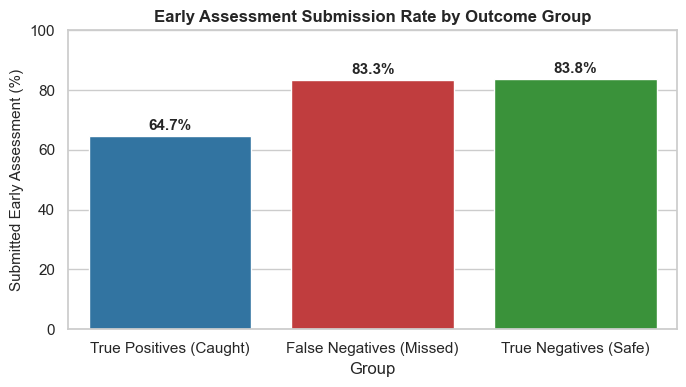

In [16]:
# Percentage of students who submitted an early assessment
submission_rate = pd.DataFrame({
    'Group': ['True Positives (Caught)', 'False Negatives (Missed)', 'True Negatives (Safe)'],
    'Has Early Submission (%)': [
        tp_df['has_early_submission'].mean() * 100,
        fn_df['has_early_submission'].mean() * 100,
        tn_df['has_early_submission'].mean() * 100
    ]
})

plt.figure(figsize=(7, 4))
ax = sns.barplot(x='Group', y='Has Early Submission (%)', data=submission_rate, palette=['#1f77b4', '#d62728', '#2ca02c'])
plt.title('Early Assessment Submission Rate by Outcome Group', fontsize=12, weight='bold')
plt.ylabel('Submitted Early Assessment (%)', fontsize=11)
plt.ylim(0, 100)

for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2, h + 2), ha='center', weight='bold')

plt.tight_layout()
plt.show()


### Early Assessment Score Distribution Among False Negatives

**Note on Missing Scores:** In OULAD, students without an early submission do not have a recorded score. We explicitly preserve missing values rather than replacing them with zero, ensuring that early score statistics accurately represent only students who completed an assessment.


In [17]:
# Detailed breakdown of early assessment scores for False Negatives
fn_total = len(fn_df)
fn_non_missing = fn_df['early_avg_score'].notna().sum()
fn_missing = fn_df['early_avg_score'].isna().sum()
fn_ge_70 = (fn_df['early_avg_score'] >= 70).sum()

pct_non_missing = (fn_ge_70 / fn_non_missing) * 100
pct_total = (fn_ge_70 / fn_total) * 100

fn_score_stats = pd.DataFrame({
    'Metric / Category': [
        'Total False Negative Enrollments',
        'Enrollments with Non-Missing Early Score',
        'Enrollments with Missing Early Score (No Submission)',
        'Enrollments Scoring >= 70 (Good or Distinction)',
        'Percentage Scoring >= 70 (Denominator: Non-Missing Scores)',
        'Percentage Scoring >= 70 (Denominator: All False Negatives)'
    ],
    'Value': [
        f"{fn_total:,}",
        f"{fn_non_missing:,} ({fn_non_missing/fn_total*100:.2f}%)",
        f"{fn_missing:,} ({fn_missing/fn_total*100:.2f}%)",
        f"{fn_ge_70:,}",
        f"{pct_non_missing:.2f}%",
        f"{pct_total:.2f}%"
    ]
})
fn_score_stats


,Metric / Category,Value
0,Total False Negative Enrollments,630
1,Enrollments with Non-Missing Early Score,524 (83.17%)
2,Enrollments with Missing Early Score (No Submi...,106 (16.83%)
3,Enrollments Scoring >= 70 (Good or Distinction),416
4,Percentage Scoring >= 70 (Denominator: Non-Mis...,79.39%
5,Percentage Scoring >= 70 (Denominator: All Fal...,66.03%


> **What does this tell us about False Negatives?**
> 1. **Relatively Strong Early Engagement:** False Negatives had an average of **14.1 active days** and **465 total clicks** by Day 30—substantially higher than True Positives (**7.1 active days** and **180 clicks**) and close to passing students (**15.6 active days**).
> 2. **Strong Early Academic Performance:** Over **83.17%** of False Negatives ($524$ out of $630$) submitted an early assessment on time, achieving an average score of **80.56**.
> 3. **High Proportion of High Early Scores:** Among False Negatives with recorded scores, **79.39%** ($416$ out of $524$) scored $70$ or above. Across all $630$ False Negatives (including those without submissions), **66.03%** scored $70$ or above.
> 4. **Early Indicators vs. Final Outcomes:** These enrollments eventually received an At Risk outcome (Fail or post-Day 30 withdrawal), despite showing relatively strong early engagement and assessment performance during the first 30 days.
> 5. **Information Limits at Day 30:** The available Day 30 features may not capture all factors associated with later academic outcomes. Possible explanations include changes in student engagement after Day 30, increasing course difficulty, personal or health circumstances, employment changes, or other life factors not represented in the dataset. These are hypotheses rather than verified causes. This highlights that an early Day 30 snapshot cannot observe changes that develop later in the semester, suggesting that early-warning tools should be complemented by subsequent monitoring checkpoints.


---
## 10. Error Analysis Across Student Groups

To ensure our predictive model functions equitably and transparently, we evaluate error rates across student subgroups:
1. `highest_education` (Prior educational qualifications)
2. `gender`
3. `age_band`
4. `disability`
5. `num_of_prev_attempts`

### Methodological Rule: Correct Denominators & Sample Sizes
* **Recall (Sensitivity):** $\frac{\text{TP}}{\text{Actual At Risk}} = \frac{\text{TP}}{\text{TP} + \text{FN}}$. Measures what percentage of struggling students within the group were caught.
* **False Positive Rate (FPR):** $\frac{\text{FP}}{\text{Actual Not At Risk}} = \frac{\text{FP}}{\text{FP} + \text{TN}}$. Measures what percentage of passing students within the group were falsely alarmed.
* **Sample Size Warning:** We report total group sizes ($N$) to avoid over-interpreting percentages from small sample categories (such as *No Formal Qualifications* or *Post Graduate*).


In [18]:
# Define a simple helper function to calculate subgroup error metrics
def compute_group_metrics(data, group_col):
    records = []
    for category, group in data.groupby(group_col, observed=False):
        total_enrollments = len(group)
        actual_at_risk = (group['target'] == 1).sum()
        actual_not_risk = (group['target'] == 0).sum()
        
        tp = ((group['target'] == 1) & (group['predicted_target'] == 1)).sum()
        fn = ((group['target'] == 1) & (group['predicted_target'] == 0)).sum()
        fp = ((group['target'] == 0) & (group['predicted_target'] == 1)).sum()
        tn = ((group['target'] == 0) & (group['predicted_target'] == 0)).sum()
        
        recall = tp / actual_at_risk if actual_at_risk > 0 else np.nan
        fpr = fp / actual_not_risk if actual_not_risk > 0 else np.nan
        
        records.append({
            'Category': category,
            'Total Enrollments': total_enrollments,
            'Actual At Risk': actual_at_risk,
            'False Negatives (Missed)': fn,
            'Recall (Sensitivity)': round(recall, 4),
            'False Positives (Alarms)': fp,
            'False Positive Rate': round(fpr, 4)
        })
    return pd.DataFrame(records)

print("Subgroup evaluation utility ready!")


Subgroup evaluation utility ready!


### 10.1 Prior Education Subgroup Analysis (`highest_education`)


In [19]:
edu_metrics = compute_group_metrics(test_results_df, 'highest_education')
edu_metrics


,Category,Total Enrollments,Actual At Risk,False Negatives (Missed),Recall (Sensitivity),False Positives (Alarms),False Positive Rate
0,A Level or Equivalent,2418,924,315,0.6591,390,0.2610
1,HE Qualification,852,304,110,0.6382,118,0.2153
2,Lower Than A Level,2093,1096,192,0.8248,486,0.4875
3,No Formal quals,50,30,3,0.9000,15,0.7500
4,Post Graduate Qualification,49,15,10,0.3333,6,0.1765


### 10.2 Gender Subgroup Analysis (`gender`)


In [20]:
gender_metrics = compute_group_metrics(test_results_df, 'gender')
gender_metrics


,Category,Total Enrollments,Actual At Risk,False Negatives (Missed),Recall (Sensitivity),False Positives (Alarms),False Positive Rate
0,F,2468,1059,346,0.6733,454,0.3222
1,M,2994,1310,284,0.7832,561,0.3331


### 10.3 Age Band Subgroup Analysis (`age_band`)


In [21]:
age_metrics = compute_group_metrics(test_results_df, 'age_band')
age_metrics


,Category,Total Enrollments,Actual At Risk,False Negatives (Missed),Recall (Sensitivity),False Positives (Alarms),False Positive Rate
0,0-35,3758,1701,383,0.7748,735,0.3573
1,35-55,1666,657,241,0.6332,273,0.2706
2,55<=,38,11,6,0.4545,7,0.2593


### 10.4 Disability Subgroup Analysis (`disability`)


In [22]:
disability_metrics = compute_group_metrics(test_results_df, 'disability')
disability_metrics


,Category,Total Enrollments,Actual At Risk,False Negatives (Missed),Recall (Sensitivity),False Positives (Alarms),False Positive Rate
0,N,4946,2087,587,0.7187,901,0.3151
1,Y,516,282,43,0.8475,114,0.4872


### 10.5 Previous Attempts Subgroup Analysis (`num_of_prev_attempts`)


In [23]:
attempts_metrics = compute_group_metrics(test_results_df, 'num_of_prev_attempts')
attempts_metrics


,Category,Total Enrollments,Actual At Risk,False Negatives (Missed),Recall (Sensitivity),False Positives (Alarms),False Positive Rate
0,0,4779,1981,588,0.7032,840,0.3002
1,1,538,290,34,0.8828,136,0.5484
2,2,109,73,6,0.9178,28,0.7778
3,3,24,18,1,0.9444,6,1.0000
4,4,10,5,1,0.8000,5,1.0000
5,5,2,2,0,1.0000,0,NaN


### Visualizing Subgroup Disparities

We plot Recall and False Positive Rate across education and disability categories.


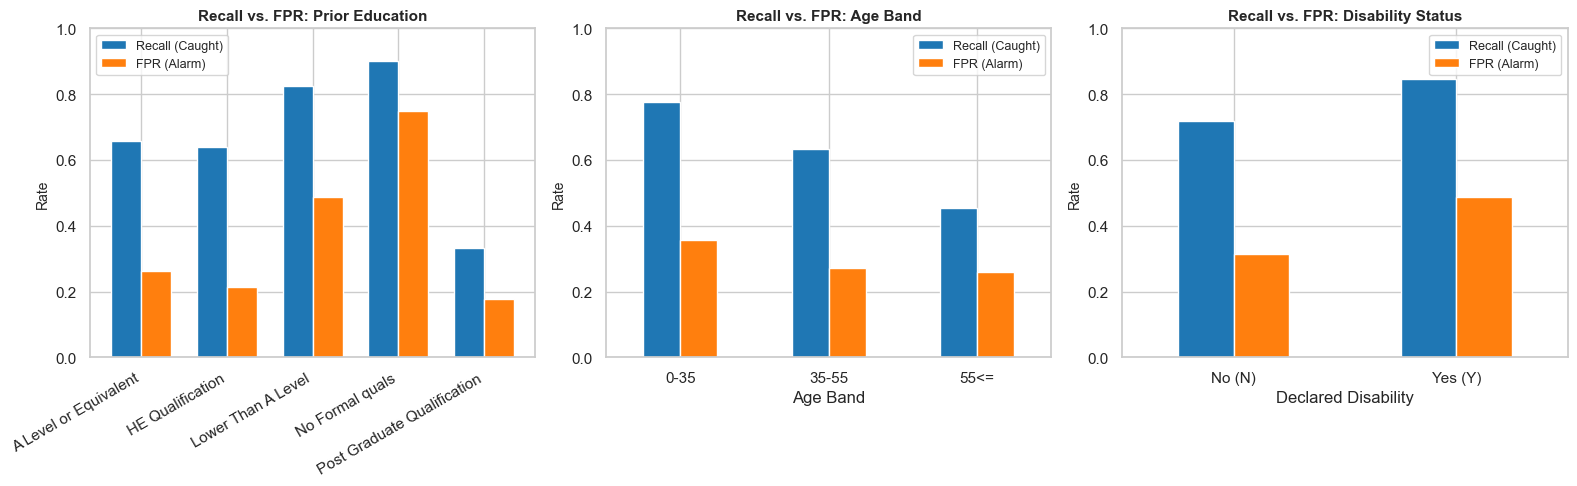

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Education
edu_plot_df = edu_metrics.set_index('Category')[['Recall (Sensitivity)', 'False Positive Rate']]
edu_plot_df.plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'], width=0.7)
axes[0].set_title('Recall vs. FPR: Prior Education', fontsize=11, weight='bold')
axes[0].set_ylabel('Rate', fontsize=10)
axes[0].set_xlabel('')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].set_ylim(0, 1.0)
axes[0].legend(['Recall (Caught)', 'FPR (Alarm)'], fontsize=9)

# Plot 2: Age Band
age_plot_df = age_metrics.set_index('Category')[['Recall (Sensitivity)', 'False Positive Rate']]
age_plot_df.plot(kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e'], width=0.5)
axes[1].set_title('Recall vs. FPR: Age Band', fontsize=11, weight='bold')
axes[1].set_ylabel('Rate', fontsize=10)
axes[1].set_xlabel('Age Band')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].set_ylim(0, 1.0)
axes[1].legend(['Recall (Caught)', 'FPR (Alarm)'], fontsize=9)

# Plot 3: Disability
dis_plot_df = disability_metrics.set_index('Category')[['Recall (Sensitivity)', 'False Positive Rate']]
dis_plot_df.plot(kind='bar', ax=axes[2], color=['#1f77b4', '#ff7f0e'], width=0.5)
axes[2].set_title('Recall vs. FPR: Disability Status', fontsize=11, weight='bold')
axes[2].set_ylabel('Rate', fontsize=10)
axes[2].set_xlabel('Declared Disability')
axes[2].set_xticklabels(['No (N)', 'Yes (Y)'], rotation=0)
axes[2].set_ylim(0, 1.0)
axes[2].legend(['Recall (Caught)', 'FPR (Alarm)'], fontsize=9)

plt.tight_layout()
plt.show()


> **What does this tell us about Subgroup Disparities?**
> 1. **Highest Education:**
>    * Students entering with *Lower Than A Level* experience high Recall (**82.48%**), catching over $8$ out of $10$ struggling students. However, this comes with a high False Positive Rate (**48.75%**). Because the model learned that this qualification is historically correlated with higher attrition, it is aggressive in flagging them.
>    * Students with *A Level or Equivalent* or *HE Qualification* have lower False Positive Rates (**26.10%** and **21.53%**), but moderate Recall (**65.91%** and **63.82%**).
>    * *Sample Size Warning:* Categories *No Formal quals* ($N=50$) and *Post Graduate Qualification* ($N=49$) have very small samples. While *Post Graduate* shows low recall ($33.33\%$), this is based on only 15 at-risk students and should not be over-interpreted.
> 2. **Age Band:**
>    * **0–35 Band ($N = 3,758$):** Represents $68.8\%$ of the test set. Actual at-risk enrollments = $1,701$. The model identified $1,318$ at-risk enrollments (**Recall = 77.48%**, $383$ False Negatives). Among the $2,057$ actually not-at-risk enrollments, $735$ were flagged (**False Positive Rate = 35.73%**).
>    * **35–55 Band ($N = 1,666$):** Actual at-risk enrollments = $657$. The model caught $416$ (**Recall = 63.32%**, $241$ False Negatives), with $273$ false alarms among $1,009$ passing students (**False Positive Rate = 27.06%**).
>    * **55<= Band ($N = 38$):** *Small sample warning!* Only 38 test enrollments (11 actual at-risk). The model caught 5 (**Recall = 45.45%**, 6 False Negatives), with 7 false alarms (**False Positive Rate = 25.93%**). Due to the very small sample size, these rates should not be generalized.
> 3. **Gender:**
>    * Recall is higher for males (**78.32%**) than females (**67.33%**), while False Positive Rates are virtually identical (**33.31%** vs **32.22%**). In this cohort, male students had steeper early drop-offs, making their risk signals more pronounced at Day 30.
> 4. **Disability Status:**
>    * Students with a declared disability have higher Recall (**84.75%**) than students without (**71.87%**), but also a higher False Positive Rate (**48.72%** vs **31.51%**).
> 5. **Previous Attempts:**
>    * Students repeating a course (`num_of_prev_attempts >= 1`) have very high recall ($88.28\%$ to $94.44\%$), but elevated false alarm rates ($54.84\%$ to $77.78\%$).
> 6. **Ethical & Fair Use Guideline:** Demographic correlations reflect historical structural disparities, not inherent capability. Advisors must use these predictions to offer support, never to discourage students or lower expectations.


---
## 11. Engagement and Early Assessment Performance Analysis

We now investigate how error rates vary across specific behavioral and academic bands:
* `active_days`: Days the student logged into the virtual learning environment on or before Day 30.
* `total_clicks`: Total interaction clicks on course materials.
* `early_avg_score`: Score on early assessments submitted on or before Day 30.
* `has_early_submission`: Whether the student submitted any early assessment.

### Preserving Missing Values
**Critical Rule:** In OULAD, students who did not submit an assessment do not have a score. We **do not replace missing scores with zero**; instead, we categorize them into a dedicated group: `No Early Submission`.


In [25]:
# Create score categories, explicitly preserving missing values as 'No Early Submission'
def categorize_score(score):
    if pd.isna(score):
        return 'No Early Submission'
    elif score < 50:
        return '< 50 (Fail Score)'
    elif score < 70:
        return '50-69 (Pass Score)'
    elif score < 85:
        return '70-84 (Good Score)'
    else:
        return '85-100 (Distinction Score)'

test_results_df['score_category'] = test_results_df['early_avg_score'].apply(categorize_score)

# Create active days bins
test_results_df['active_days_bin'] = pd.cut(
    test_results_df['active_days'],
    bins=[-1, 5, 10, 15, 20, 100],
    labels=['0-5 days', '6-10 days', '11-15 days', '16-20 days', '21+ days']
)

# Create total clicks bins
test_results_df['clicks_bin'] = pd.cut(
    test_results_df['total_clicks'],
    bins=[-1, 50, 150, 300, 600, 100000],
    labels=['0-50 clicks', '51-150 clicks', '151-300 clicks', '301-600 clicks', '601+ clicks']
)

print("Diagnostic bins created successfully!")


Diagnostic bins created successfully!


### Error Breakdown by Early Assessment Score Category


In [26]:
# Cross-tabulation of score categories and error types
score_ct = pd.crosstab(
    test_results_df['score_category'],
    test_results_df['error_type'],
    margins=True,
    margins_name='Total'
)

# Reorder rows logically
score_order = ['No Early Submission', '< 50 (Fail Score)', '50-69 (Pass Score)', '70-84 (Good Score)', '85-100 (Distinction Score)', 'Total']
score_ct = score_ct.reindex(score_order)
score_ct


error_type,False Negative,False Positive,True Negative,True Positive,Total
score_category,,,,,
No Early Submission,106,230,337,614,1287
< 50 (Fail Score),7,120,18,254,399
50-69 (Pass Score),101,229,186,450,966
70-84 (Good Score),202,300,638,321,1461
85-100 (Distinction Score),214,136,899,100,1349
Total,630,1015,2078,1739,5462


### Visualizing Error Composition Across Score Bands


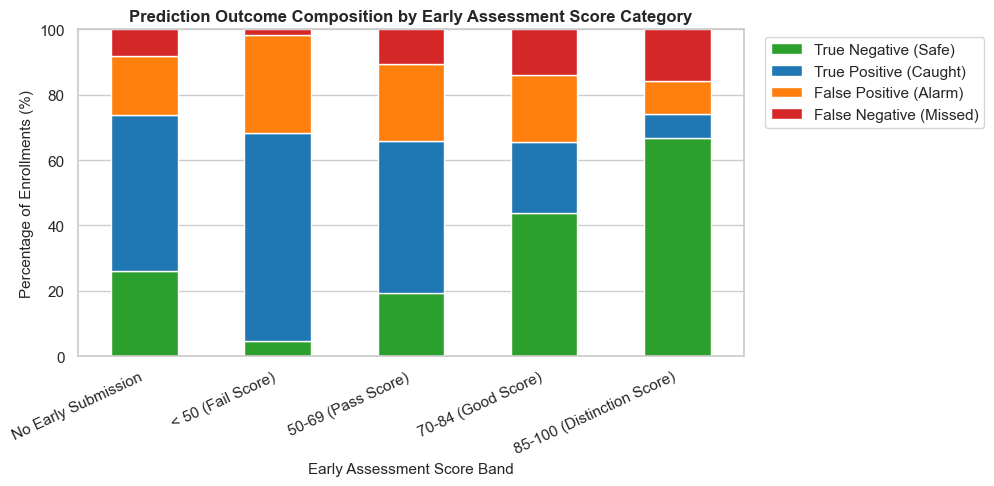

In [27]:
# Exclude 'Total' margin for plotting
score_plot_data = score_ct.loc[['No Early Submission', '< 50 (Fail Score)', '50-69 (Pass Score)', '70-84 (Good Score)', '85-100 (Distinction Score)'], order_list]

score_plot_pct = score_plot_data.div(score_plot_data.sum(axis=1), axis=0) * 100

ax = score_plot_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color=[palette_dict[k] for k in order_list]
)

plt.title('Prediction Outcome Composition by Early Assessment Score Category', fontsize=12, weight='bold')
plt.xlabel('Early Assessment Score Band', fontsize=11)
plt.ylabel('Percentage of Enrollments (%)', fontsize=11)
plt.legend(['True Negative (Safe)', 'True Positive (Caught)', 'False Positive (Alarm)', 'False Negative (Missed)'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


> **What does this tell us about Early Assessment Scores?**
> * **No Early Submission:** Students with no early submission represent a high-risk group. **47.7%** are True Positives and **17.9%** are False Positives. Over **85%** of actual at-risk students without an early submission are successfully caught ($614$ caught vs $106$ missed).
> * **Low Scores (< 50):** If a student fails the first assessment, the model catches **97.3%** of those who ultimately fail ($254$ caught vs only $7$ missed).
> * **High Scores (70+):** This is where **False Negatives cluster**. Among students scoring $70-84$, there are $202$ False Negatives; among students scoring $85-100$, there are $214$ False Negatives. In total, **416 out of 630 False Negatives (66.0%)** scored $70$ or higher on their early assessment!
> * **Insight:** Students who perform well on Assignment 1 lull the model into predicting safety, but a strong start does not immunize a student against later-term academic difficulties.


### Error Breakdown by Active Days on the VLE


In [28]:
# Cross-tabulation of active days and error types
active_ct = pd.crosstab(
    test_results_df['active_days_bin'],
    test_results_df['error_type'],
    margins=True,
    margins_name='Total'
)
active_ct.reindex(['0-5 days', '6-10 days', '11-15 days', '16-20 days', '21+ days', 'Total'])


error_type,False Negative,False Positive,True Negative,True Positive,Total
active_days_bin,,,,,
0-5 days,79,231,130,601,1041
6-10 days,97,297,231,482,1107
11-15 days,92,250,302,320,964
16-20 days,83,130,378,185,776
21+ days,279,107,1037,151,1574
Total,630,1015,2078,1739,5462


> **What does this tell us about Active Days?**
> * **0–5 Active Days:** High-risk group. Caught $601$ at-risk students and missed only $79$ ($88.4\%$ recall). However, $231$ students were False Positives (slow starters who logged in infrequently early on but passed).
> * **21+ Active Days:** Accounts for **44.3% of all False Negatives** ($279$ out of $630$). These students logged in regularly during the first month, yet subsequently failed or dropped out.


---
## 12. Prediction Probability Analysis & The Borderline Zone

Logistic Regression outputs continuous predicted probabilities $P(\text{At Risk}) \in [0, 1]$. We convert these probabilities into binary decisions using our tuned threshold of **0.40**.

In this section, we analyze the distribution of predicted probabilities across the four outcome groups to investigate:
1. Are False Positives and False Negatives concentrated near the 0.40 threshold?
2. How many errors fall into a "borderline" or uncertain zone ($0.35 \le P \le 0.45$)?


In [29]:
# Summary statistics of predicted probability by error type
prob_stats = test_results_df.groupby('error_type')['predicted_probability'].describe()[
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
].reindex(order_list)

prob_stats.round(4)


,count,mean,std,min,25%,50%,75%,max
error_type,,,,,,,,
True Negative,2078.0,0.2325,0.0964,0.0153,0.1574,0.2359,0.3122,0.3998
True Positive,1739.0,0.6758,0.1732,0.4000,0.5249,0.6548,0.8294,0.9939
False Positive,1015.0,0.5579,0.1246,0.4001,0.4570,0.5323,0.6297,0.9557
False Negative,630.0,0.2768,0.0880,0.0222,0.2124,0.2925,0.3524,0.3994


### Box Plot: Predicted Probability by Prediction Outcome Group


C:\Users\vhres\AppData\Local\Temp\ipykernel_13184\208004911.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


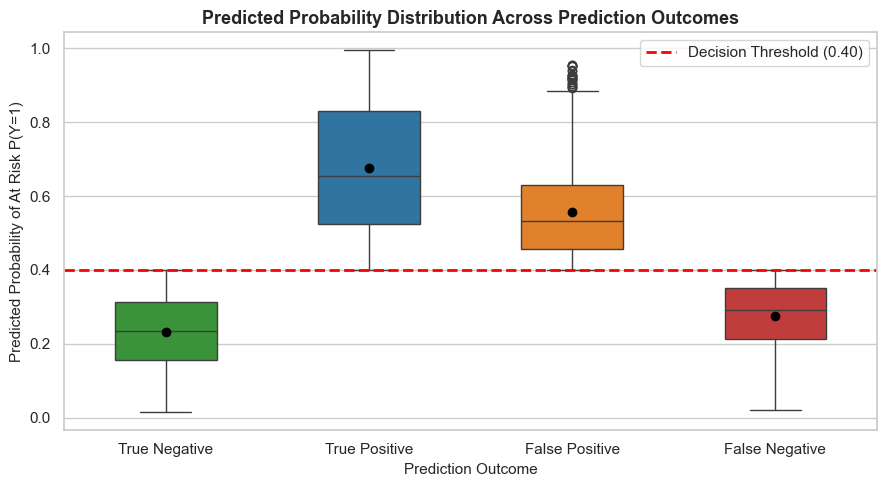

In [30]:
plt.figure(figsize=(9, 5))
ax = sns.boxplot(
    x='error_type',
    y='predicted_probability',
    data=test_results_df,
    order=order_list,
    palette=palette_dict,
    width=0.5,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'black', 'markeredgecolor': 'black'}
)

# Plot decision threshold line
plt.axhline(
    decision_threshold, 
    color='red', 
    linestyle='--', 
    linewidth=2, 
    label=f'Decision Threshold ({decision_threshold:.2f})'
)

plt.title('Predicted Probability Distribution Across Prediction Outcomes', fontsize=13, weight='bold')
plt.xlabel('Prediction Outcome', fontsize=11)
plt.ylabel('Predicted Probability of At Risk P(Y=1)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


### Density Distributions of Predicted Probabilities


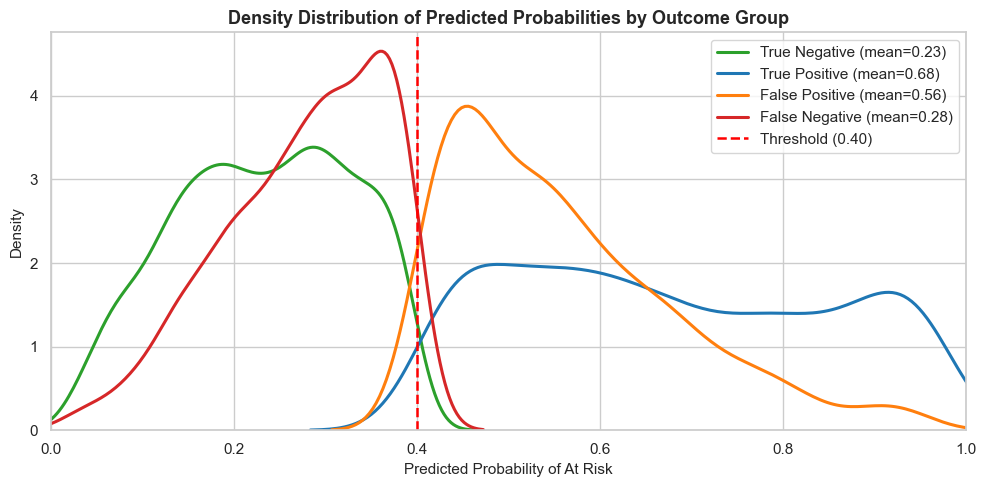

In [31]:
plt.figure(figsize=(10, 5))

for et in order_list:
    subset = test_results_df[test_results_df['error_type'] == et]
    sns.kdeplot(
        subset['predicted_probability'],
        label=f"{et} (mean={subset['predicted_probability'].mean():.2f})",
        color=palette_dict[et],
        linewidth=2.2
    )

plt.axvline(
    decision_threshold, 
    color='red', 
    linestyle='--', 
    linewidth=1.8, 
    label=f'Threshold ({decision_threshold:.2f})'
)

plt.title('Density Distribution of Predicted Probabilities by Outcome Group', fontsize=13, weight='bold')
plt.xlabel('Predicted Probability of At Risk', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.xlim(0, 1)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


### Quantifying the Borderline Zone ($0.35 \le P \le 0.45$)

Many classification errors occur when a student's predicted probability is close to the cutoff.


In [32]:
# Define borderline zone: within +/- 0.05 of threshold
borderline_mask = (test_results_df['predicted_probability'] >= 0.35) & (test_results_df['predicted_probability'] <= 0.45)
borderline_df = test_results_df[borderline_mask]

print(f"Total enrollments in borderline zone [0.35, 0.45]: {len(borderline_df):,} ({len(borderline_df)/len(test_results_df)*100:.1f}%)")
print("\nOutcome breakdown within borderline zone:")
borderline_counts = borderline_df['error_type'].value_counts()
for et, count in borderline_counts.items():
    pct_of_error = count / outcome_counts[et] * 100
    print(f"  {et:15s}: {count:3d} records ({pct_of_error:.1f}% of all {et}s)")


Total enrollments in borderline zone [0.35, 0.45]: 841 (15.4%)

Outcome breakdown within borderline zone:
  True Negative  : 282 records (13.6% of all True Negatives)
  False Positive : 216 records (21.3% of all False Positives)
  True Positive  : 173 records (9.9% of all True Positives)
  False Negative : 170 records (27.0% of all False Negatives)


> **What does this tell us about Prediction Probabilities?**
> 1. **Well-Separated Correct Groups:** True Positives (mean $0.68$, median $0.65$) and True Negatives (mean $0.23$, median $0.24$) are decisively separated by the model.
> 2. **Proximity to Cutoff:**
>    * The median False Negative probability is **0.29**, and over **27.0%** of all False Negatives ($170$ records) sit within $0.05$ of the threshold.
>    * The median False Positive probability is **0.53**, and **21.3%** of all False Positives ($216$ records) sit within $0.05$ of the threshold.
> 3. **The Borderline Zone:** A total of **841 enrollments (15.4% of the test set)** have predicted probabilities between $0.35$ and $0.45$. In this range, the model is inherently uncertain.
> 4. **Proposed Three-Tier Operational Categories (Separate from Binary Model Prediction):**
>    * The primary classification model strictly uses the **fixed decision threshold of 0.40** for binary prediction (evaluating Recall, Precision, and F1).
>    * For educator workflow support, we propose a **three-tier operational categorization** to help triage intervention priority:
>      * **High Priority ($P \ge 0.50$):** Strong early risk indicators; priority candidate for direct advisor contact or tutoring referral.
>      * **Watchlist / Moderate ($0.35 \le P < 0.50$):** Borderline probability range with higher classification uncertainty; candidate for checking recent LMS activity and monitoring upcoming assignment submission.
>      * **Low Risk ($P < 0.35$):** Low early risk signals; standard general course communications.
>    * **Important Clarification:** These three tiers are **proposed operational intervention categories requiring further practical validation, not proven risk levels**. They serve as practical workflow guidelines for teachers rather than definitive assessments of student capability.


---
## 13. Key Findings, Model Limitations & Improvement Opportunities

### Summary of Key Findings

| Diagnostic Area | Key Finding | Educational Significance |
|---|---|---|
| **False Negatives (Missed Risk)** | $630$ enrollments ($26.59\%$ of at-risk cohort). Average active days = $14.1$; $83.17\%$ submitted early assignment; $79.39\%$ of scored submissions achieved $\ge 70$ (mean = $80.56$). | These enrollments eventually received an At Risk outcome **despite showing relatively strong early engagement and scores at Day 30**. The available Day 30 features may not capture factors associated with later academic outcomes (e.g., changes in study habits, unobserved personal circumstances, or later course difficulty). |
| **False Positives (False Alarms)** | $1,015$ enrollments ($18.58\%$ of test set). Average active days = $8.5$; early clicks = $235$; early score = $64.91$. | These enrollments showed lower Day 30 activity and scores, but ultimately achieved Pass or Distinction. The Day 30 model flagged them based on early associations; subsequent adjustments or external support not recorded in the data are possible explanations. Reaching out with friendly support is low-risk. |
| **Prior Educational Background** | Students with *Lower Than A Level* ($N=2,093$) had high Recall ($82.48\%$) but high False Positive Rate ($48.75\%$). | Model heavily weights entry qualifications. Passing students in this group face frequent false alarms. |
| **Age Band Disparities** | 0-35 ($N=3,758$): Recall = $77.48\%$, FPR = $35.73\%$. 35-55 ($N=1,666$): Recall = $63.32\%$, FPR = $27.06\%$. 55<= ($N=38$, small sample): Recall = $45.45\%$, FPR = $25.93\%$. | Sensitivity was higher among younger enrollments (0-35), while older groups had lower false alarm rates. Small sample sizes in the 55<= group require caution. |
| **Declared Disability** | Higher Recall ($84.75\%$) but higher FPR ($48.72\%$) compared to students without declared disability ($N=516$). | Model applies a positive risk coefficient. Interventions must offer accommodations, not lower expectations. |
| **The Borderline Zone** | $841$ enrollments ($15.4\%$ of test set) fall in $P \in [0.35, 0.45]$, accounting for nearly a quarter of all model errors. | Binary classifications near the threshold are sensitive. A three-tier operational category system is proposed for triage. |

---

### Model Limitations

1. **Static Time Horizon (Day 30 Cutoff):**
   Predicting final academic outcomes from the first 30 days of a multi-month course has an inherent ceiling. The available Day 30 features cannot observe changes in student engagement, escalating course difficulty, or life circumstances that arise weeks or months later.
2. **Missing Granular Behavioral Context:**
   Our features summarize aggregate counts (clicks, active days, scores). The model lacks qualitative context:
   * Did the student post questions in discussion forums asking for help?
   * Were assessment submissions submitted at the deadline or days early?
   * Did the student download study guides or only skim the homepage?
3. **Correlation vs. Causation in Demographics:**
   Demographic features (education level, age, IMD band) reflect historical educational inequities, not causal determinants of individual talent or effort. Using demographics in predictive modeling requires strict ethical governance.
4. **Small Sample Subgroups:**
   Certain subgroups (e.g., *Post Graduate Qualification* $N=49$, *No Formal Qualifications* $N=50$, *Age 55<=* $N=38$) have very small representation, leading to unstable error rate estimates.

---

### Opportunities for Improvement

1. **Multi-Stage Rolling Predictions:**
   Complement the Day 30 early warning with subsequent prediction checkpoints at **Day 60** (after mid-term exams) and **Day 90**. Students who started strong but disengaged would be caught at the Day 60 checkpoint.
2. **Trajectory & Trend Features:**
   Instead of static aggregate sums, calculate **velocity features**: e.g., ratio of Day 16–30 clicks to Day 1–15 clicks to detect early disengagement trends.
3. **Forum & Interaction NLP Features:**
   Incorporate sentiment analysis or question-asking frequency from student discussion forums.
4. **Three-Tier Operational Workflow in the Application:**
   Complement the primary **0.40 decision threshold** with proposed triage categories for educators: **High Priority ($P \ge 0.50$)**, **Watchlist / Moderate ($0.35 \le P < 0.50$)**, and **Low Risk ($P < 0.35$)**. These are proposed operational tiers requiring further practical validation, designed to help educators prioritize attention without altering the underlying classification threshold.


---
## 14. Conclusion & Operational Recommendations for Educators

### Conclusion
Our detailed error analysis demonstrates that the **Logistic Regression early warning model** is an effective, practical screening tool for early student support:
* It successfully identifies **73.41%** of struggling enrollments at an early stage (Day 30), allowing educators to intervene weeks before major summative exams.
* Its error patterns reflect the nature of early-course data:
  * **False Positives** correspond to enrollments with lower early engagement metrics that nonetheless resulted in successful completion.
  * **False Negatives** correspond to enrollments with strong early engagement and scores that eventually resulted in failure or withdrawal.
* The available Day 30 features do not capture unrecorded post-cutoff changes, making it essential to view model predictions as screening signals rather than definitive outcomes.

### Practical Guidelines for System Deployment
1. **Human-in-the-Loop:** The model is a **decision-support tool**, not an automated evaluator. No student should ever be penalized, graded, or judged based on model risk scores.
2. **Supportive Framing:** Interventions triggered by the system should be framed positively (e.g., *"We wanted to check in and see how your first month is going, and remind you of free tutoring resources"*), ensuring that False Positives receive a welcoming and helpful experience.
3. **Ongoing Monitoring:** Low-risk students must still be monitored by educators during mid-terms and finals, recognizing that Day 30 cannot foresee late-semester life events.

With the error analysis complete, our model evaluation is fully validated. We are ready to proceed to building the interactive, teacher-facing **Streamlit web application** in Stage 6.
